<center><h1>Kinetic Parameters</h1></center>
<hr/>

Assigns Km (mM) and Kcat (1/s) to every PSS reaction species via a three-level lookup:

| Priority | Source | Coverage |
|---|---|---|
| **1 — Gathered** | BRENDA / SABIO-RK + CatPred estimates | ~150 catalysis reactions |
| **2 — NIB** | Manually annotated Excel file | remaining reaction types |
| **3 — Type median** | Median Km/Kcat per reaction type from NIB | fallback for unmapped reactions |
| **4 — Global median** | Median over all gathered + NIB values | last resort |

The output is a `kinetics(reaction_id)` callable serialised with `dill`.

In [1]:
import json
import statistics
from pathlib import Path
from typing import Optional

import dill # type: ignore
import numpy as np
import pandas as pd
import plotly.express as px # type: ignore

from scripts.utils import (
    PSS_REACTIONS_PATH,
    PSS_SPECIES_PATH,
    KINETIC_PARAMETERS_PATH,
    KINETIC_NIB_PARAMETERS_PATH,
    KINETIC_NIB_PARAMETERS_SHEET,
    PSS_KINETIC_PARAMETER_MAPPER,
    RED, RESET,
    plt, sns,
)

## Load

In [2]:
reactions = json.loads(Path(PSS_REACTIONS_PATH).read_text())
species   = json.loads(Path(PSS_SPECIES_PATH).read_text())

print(f"Loaded {RED}{len(species)}{RESET} species and {RED}{len(reactions)}{RESET} reactions.")

Loaded 1139 species and 864 reactions.


## Source 1 — Gathered Kinetics (BRENDA / SABIO-RK / CatPred)

Per-reaction Km and Kcat values gathered from literature databases,
with CatPred predictions filling in missing entries.

In [3]:
reactions_kinetics = pd.ExcelFile(KINETIC_PARAMETERS_PATH)

gathered_kinetics  = pd.read_excel(reactions_kinetics, 'Gathered_Final', header=[0, 1])
estimated_kinetics = pd.read_excel(reactions_kinetics, 'Estimated',      header=[0, 1, 2])

In [4]:
def _parse_values(series) -> list:
    """Flatten a Series of newline-separated value strings into a flat list."""
    return sum(series.apply(lambda x: str(x).split('\n')).values.tolist(), [])


def _first_numeric(*candidates) -> Optional[float]:
    """Return the first candidate that converts to float, or None."""
    for v in candidates:
        try:
            return float(v)
        except (ValueError, TypeError):
            continue
    return None


def get_kinetics(reaction: str, reactions: dict,
                 gathered_kinetics: pd.DataFrame,
                 estimated_kinetics: pd.DataFrame) -> dict[str, tuple]:
    """Look up Km and Kcat for each reactant of *reaction* from gathered/estimated data.

    Priority per value: BRENDA → SABIO-RK → CatPred estimate.

    Args:
        reaction:           Reaction ID.
        reactions:          PSS reactions dict.
        gathered_kinetics:  DataFrame from 'Gathered_Final' sheet.
        estimated_kinetics: DataFrame from 'Estimated' sheet.

    Returns:
        {reactant_id: (km_mM, kcat_1s)} — value is None where unavailable.

    Raises:
        ValueError: If reaction is not present in gathered_kinetics.
    """
    rxn_col = ('Unnamed: 0_level_0', 'reaction')
    if reaction not in gathered_kinetics[rxn_col].values:
        raise ValueError(f'{reaction} not found in gathered/estimated kinetics!')

    gathered  = gathered_kinetics[gathered_kinetics[rxn_col] == reaction]
    estimated = estimated_kinetics[
        estimated_kinetics[('reaction', 'Unnamed: 0_level_1', 'Unnamed: 0_level_2')] == reaction
    ]

    km_brenda    = _parse_values(gathered[('BRENDA',   'km (mM)')])
    kcat_brenda  = _parse_values(gathered[('BRENDA',   'kcat (1/s)')])
    km_sabiork   = _parse_values(gathered[('SABIO-RK', 'km (mM)')])
    kcat_sabiork = _parse_values(gathered[('SABIO-RK', 'kcat (1/s)')])
    km_est       = _parse_values(estimated[('CatPred', 'Km [mM]',   'Unnamed: 17_level_2')])
    kcat_est     = _parse_values(estimated[('CatPred', 'Kcat [1/s]','Unnamed: 18_level_2')])

    return {
        reactant: (
            _first_numeric(km_brenda[i],   km_sabiork[i],   km_est[i]   if i < len(km_est)   else None),
            _first_numeric(kcat_brenda[i], kcat_sabiork[i], kcat_est[i] if i < len(kcat_est) else None),
        )
        for i, reactant in enumerate(reactions[reaction]['reactants'])
    }

### Example

In [5]:
for rxn_id in ['rx00041', 'rx00666']:
    try:
        print(f"{RED}{rxn_id}{RESET}", get_kinetics(rxn_id, reactions, gathered_kinetics, estimated_kinetics))
    except ValueError as e:
        print(e)

rx00041 {'s_Ile_cyt_m': (0.03, 0.01588), 's_JA_cyt_m': (0.19, 0.22052)}
rx00666 not found in gathered/estimated kinetics!


In [6]:
vals = []
for reaction in reactions:
    try: vals += list(get_kinetics(reaction, reactions, gathered_kinetics, estimated_kinetics).values())
    except: pass

In [7]:
kms, kcats = zip(*vals)

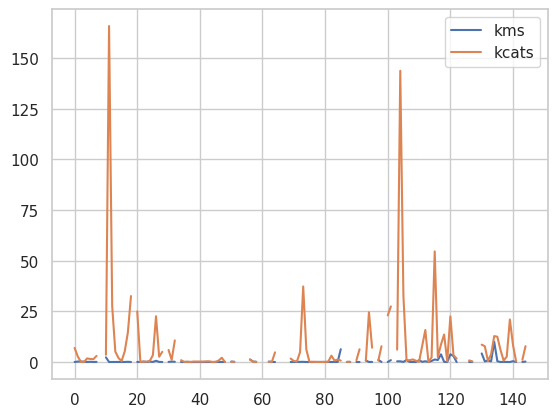

In [8]:
plt.figure()
plt.plot(kms, label='kms')
plt.plot(kcats, label='kcats')
plt.legend()
plt.show()

## Source 2 — NIB Annotated Kinetics

Manually curated kinetic parameters covering a broader set of reaction types.

In [15]:
nib_reactions = pd.read_excel(
    KINETIC_NIB_PARAMETERS_PATH,
    sheet_name=KINETIC_NIB_PARAMETERS_SHEET,
    header=[0, 1],
)
# Normalise unnamed top-level columns to a single space key
nib_reactions.columns = pd.MultiIndex.from_tuples([
    (c[0] if c[0] in ('Km', 'Kcat') else ' ', *c[1:])
    for c in nib_reactions.columns
])
nib_reactions = nib_reactions[[
    (' ', 'reaction_id'),
    (' ', 'reaction_type'),
    (' ', 'reaction_effect'),
    (' ', 'rate_law (SBO)'),
    (' ', 'Equation (Antimony)'),
    ('Km',   'lowerBound/upperBound/nominalValue 2'),
    ('Km',   'Units 2'),
    ('Kcat', 'lowerBound/upperBound/nominalValue'),
    ('Kcat', 'Units'),
]]
nib_reactions.head()

\
  reaction_id            reaction_type reaction_effect rate_law (SBO)   
0     rx00985  binding/oligomerisation      activation            NaN   
1     rx00984       protein activation      activation            NaN   
2     rx00983  binding/oligomerisation      activation            NaN   
3     rx00982       protein activation      activation            NaN   
4     rx00981  binding/oligomerisation      activation            NaN   

                                                        Km          \
  Equation (Antimony) lowerBound/upperBound/nominalValue 2 Units 2   
0                 NaN                                  NaN     NaN   
1                 NaN                                  NaN     NaN   
2                 NaN                                  NaN     NaN   
3                 NaN                                  NaN     NaN   
4                 NaN                                  NaN     NaN   

                                Kcat        
  lowerBound/upperBound/nominalValue Units  
0                                NaN   NaN  
1                                NaN   NaN  
2                                NaN   NaN  
3                                NaN   NaN  
4                                NaN   NaN

In [16]:
nib_reactions.columns

MultiIndex([(   ' ',                          'reaction_id'),
            (   ' ',                        'reaction_type'),
            (   ' ',                      'reaction_effect'),
            (   ' ',                       'rate_law (SBO)'),
            (   ' ',                  'Equation (Antimony)'),
            (  'Km', 'lowerBound/upperBound/nominalValue 2'),
            (  'Km',                              'Units 2'),
            ('Kcat',   'lowerBound/upperBound/nominalValue'),
            ('Kcat',                                'Units')],
           )

In [42]:
def km_unit_conversion(
    value, unit, molar_mass: Optional[float] = None,
    verbose: bool = False, reaction: Optional[str] = None,
) -> Optional[float]:
    """Convert Km to mM from various source units.

    Args:
        value:       Raw Km value.
        unit:        Unit string (e.g. 'nM', 'uM', 'ppm', 'µMol/L').
        molar_mass:  Required for ppm conversion (g/mol).
        verbose:     Print warnings for unsupported/unconvertible units.
        reaction:    Reaction ID for warning messages.

    Returns:
        Km in mM, or None if conversion is not possible.
    """
    if not (value or unit):
        return value
    unit = unit.strip().lower()
    if unit == 'nm':                    return float(value) / 1e6
    if unit in ('um', 'μm', 'µmol/l'): return float(value) / 1e3
    if unit == 'mm':                    return float(value)
    if unit == 'ppm':
        if molar_mass:                  return float(value) / molar_mass
        if verbose: print(f"{reaction}: molar mass required to convert ppm → mM.")
        return None
    if verbose: print(f"{reaction}: unsupported Km unit '{unit}'.")
    return None


def kcat_unit_conversion(
    value, unit, enzyme_molar_mass: Optional[float] = None,
    enzyme_conc: Optional[float] = None,
    verbose: bool = False, reaction: Optional[str] = None,
) -> Optional[float]:
    """Convert Kcat to 1/s from various source units.

    Args:
        value:              Raw Kcat value.
        unit:               Unit string (e.g. '1/min', 'µM/mg*min').
        enzyme_molar_mass:  In g/mol — required for µM/mg*min conversion.
        enzyme_conc:        In nM — required for nM/min conversion.
        verbose:            Print warnings.
        reaction:           Reaction ID for warning messages.

    Returns:
        Kcat in 1/s, or None if conversion is not possible.
    """
    if not (value or unit):
        return value
    unit = unit.strip().lower()
    if unit == '1/s':   return float(value)
    if unit == '1/min': return float(value) / 60
    if unit in ('µm/mg*min', 'um/mg*min'):
        if enzyme_molar_mass: return (float(value) * enzyme_molar_mass) / 60
        if verbose: print(f"{reaction}: molar mass required for µM/mg*min conversion.")
        return None
    if unit == 'nm/min':
        if enzyme_conc: return float(value) / enzyme_conc
        if verbose: print(f"{reaction}: enzyme concentration required for nM/min conversion.")
        return None
    if verbose: print(f"{reaction}: unsupported Kcat unit '{unit}'.")
    return None

In [43]:
def _parse_lun(raw) -> Optional[str]:
    """Extract the nominal (or best available) value from a 'lower/upper/nominal' string."""    
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    parts = str(raw).split('/')
    # prefer nominal (last), fall back left to right
    for p in reversed(parts):
        try:
            float(p)
            return p
        except ValueError:
            continue
    return None


def get_kinetics_nib(
    reaction: str,
    reactions: dict,
    nib_reactions: pd.DataFrame,
    verbose: bool = False,
) -> dict[str, tuple]:
    """Look up Km and Kcat for each reactant of *reaction* from the NIB file.

    A single Km/Kcat pair is shared across all reactants of the reaction,
    since the NIB file provides at most one value per reaction.

    Args:
        reaction:     Reaction ID.
        reactions:    PSS reactions dict.
        nib_reactions: DataFrame from the NIB Excel sheet.
        verbose:      Forward to unit conversion functions.

    Returns:
        {reactant_id: (km_mM, kcat_1s)} — value is None where unavailable.

    Raises:
        ValueError: If reaction is not present in nib_reactions.
    """
    if reaction not in nib_reactions[' ', 'reaction_id'].values:
        raise ValueError(f'{reaction} not found in NIB reactions!')

    row      = nib_reactions[nib_reactions[(' ', 'reaction_id')] == reaction]
    km_unit  = row['Km',   'Units'].values[0]
    kcat_unit = row['Kcat', 'Units'].values[0]

    km_unit  = None if (km_unit  is None or (isinstance(km_unit,  float) and np.isnan(km_unit)))  else km_unit
    kcat_unit = None if (kcat_unit is None or (isinstance(kcat_unit, float) and np.isnan(kcat_unit))) else kcat_unit

    km   = km_unit_conversion(
        _parse_lun(row['Km',   'lowerBound/upperBound/nominalValue'].values[0]),
        km_unit, verbose=verbose, reaction=reaction,
    )
    kcat = kcat_unit_conversion(
        _parse_lun(row['Kcat', 'lowerBound/upperBound/nominalValue'].values[0]),
        kcat_unit, verbose=verbose, reaction=reaction,
    )

    return {reactant: (km, kcat) for reactant in reactions[reaction]['reactants']}

### Example

In [44]:
for rxn_id in ['rx00319', 'rx00041']:
    try:
        print(f"{RED}{rxn_id}{RESET}", get_kinetics_nib(rxn_id, reactions, nib_reactions))
    except ValueError as e:
        print(e)

rx00319 {'s_SCF_cyt_ca': (0.00036, None), 's_D14_cyt_pa': (0.00036, None), 's_MAX2_cyt_pa': (0.00036, None)}
rx00041 {'s_Ile_cyt_m': (None, None), 's_JA_cyt_m': (None, None)}


In [66]:
for reaction in reactions:
    try: 
        vals = get_kinetics_nib(reaction, reactions, nib_reactions)
        if vals:
            print(reaction, vals)
    except: pass

rx00669 {'s_VPg_cyt_p': (None, None), 's_LHB1B1_cyt_p': (None, None)}
rx00666 {'s_VPg_cyt_p': (None, None), 's_PSB33_cyt_p': (None, None)}
rx00215 {'s_HCPro_cyt_pa': (None, None), 's_CRT_cyt_pa': (None, None)}
rx00568 {'s_OSCA1_cyt_p': (None, None)}
rx00569 {'s_AREBABF_cyt_p': (None, None)}
rx00570 {'s_ARRA_nuc_p': (None, None)}
rx00218 {'s_HCPro_cyt_pa': (None, None), 's_EDF2_cyt_p': (None, None)}
rx00219 {'s_CML_cyt_pa': (None, None), 's_HCPro_cyt_pa': (None, None)}
rx00532 {'s_CA_per_m': (None, None)}
rx00087 {'s_EDS1_nuc_pa': (None, None), 's_PAD4_nuc_pa': (None, None)}
rx00090 {'s_EDS1PAD4_nuc_ca': (None, None), 's_MPK36_cyt_pa': (None, None)}
rx00664 {'s_VPg_cyt_p': (None, None), 's_SERPIN1_cyt_p': (None, None)}
rx00665 {'s_VPg_cyt_p': (None, None), 's_clpP1_cyt_p': (None, None)}
rx00668 {'s_VPg_cyt_p': (None, None), 's_FQR1_cyt_p': (None, None)}
rx00663 {'s_VPg_cyt_p': (None, None), 's_PR3like_cyt_p': (None, None)}
rx00220 {'s_HCPro_cyt_pa': (None, None), 's_TDX_cyt_p': (None, N

In [ ]:
get_kinetics('')

## Global Fallbacks

In [10]:
def _flat_km_kcat(values_dict: dict) -> tuple[list[float], list[float]]:
    """Extract flat lists of non-None Km and Kcat values from a {reactant: (km, kcat)} dict."""
    kms   = [km   for km,   _    in values_dict.values() if km   is not None]
    kcats = [kcat for _,    kcat in values_dict.values() if kcat is not None]
    return kms, kcats

In [11]:
# Median Km / Kcat per reaction type (from NIB)
global_kinetics: dict[str, dict] = {}
for rxn_type in nib_reactions[' ', 'reaction_type'].unique():
    type_rxns = nib_reactions[nib_reactions[' ', 'reaction_type'] == rxn_type][' ', 'reaction_id'].tolist()
    kms, kcats = [], []
    for rxn_id in type_rxns:
        if rxn_id not in reactions:
            continue
        try:
            kms_r, kcats_r = _flat_km_kcat(get_kinetics_nib(rxn_id, reactions, nib_reactions))
            kms.extend(kms_r)
            kcats.extend(kcats_r)
        except ValueError:
            continue
    global_kinetics[rxn_type] = {
        'km_median':   statistics.median(kms)   if kms   else None,
        'kcat_median': statistics.median(kcats) if kcats else None,
    }

print(f"Computed type-level medians for {RED}{len(global_kinetics)}{RESET} reaction types.")
for key, val in global_kinetics.items():
    print(f'{key:<45}: {"km_median: " + str(val["km_median"]):<40}; {"kcat_median: " + str(val["kcat_median"])}')

Computed type-level medians for 10 reaction types.
binding/oligomerisation                      : km_median: 0.00036                      ; kcat_median: None
protein activation                           : km_median: 0.0029300000000000003        ; kcat_median: 1919.8311666666666
translocation                                : km_median: 0.01                         ; kcat_median: 10.0
protein deactivation                         : km_median: 4.5e-06                      ; kcat_median: 0.013500000000000002
transcriptional/translational activation     : km_median: 1.6986500000000002e-07       ; kcat_median: 16666.666666666668
catalysis                                    : km_median: None                         ; kcat_median: None
degradation/secretion                        : km_median: 5.6355000000000005e-05       ; kcat_median: 0.008841666666666666
transcriptional/translational repression     : km_median: 1.271e-05                    ; kcat_median: 0.006016666666666667
unknown          

In [12]:
# Global median over all gathered + NIB values
all_kms, all_kcats = [], []
for rxn_id in reactions:
    try:
        kms_r, kcats_r = _flat_km_kcat(get_kinetics(rxn_id, reactions, gathered_kinetics, estimated_kinetics))
    except ValueError:
        try:
            kms_r, kcats_r = _flat_km_kcat(get_kinetics_nib(rxn_id, reactions, nib_reactions))
        except ValueError:
            continue
    all_kms.extend(kms_r)
    all_kcats.extend(kcats_r)

global_median_km   = float(np.median([v for v in all_kms   if v is not None]))
global_median_kcat = float(np.median([v for v in all_kcats if v is not None]))

print(f"Global median {RED}Km{RESET}:   {RED}{global_median_km:.4e}{RESET} mM")
print(f"Global median {RED}Kcat{RESET}: {RED}{global_median_kcat:.4e}{RESET} 1/s")

Global median Km:   1.3300e-02 mM
Global median Kcat: 1.0289e+00 1/s


### Visualise global Km / Kcat per reaction type

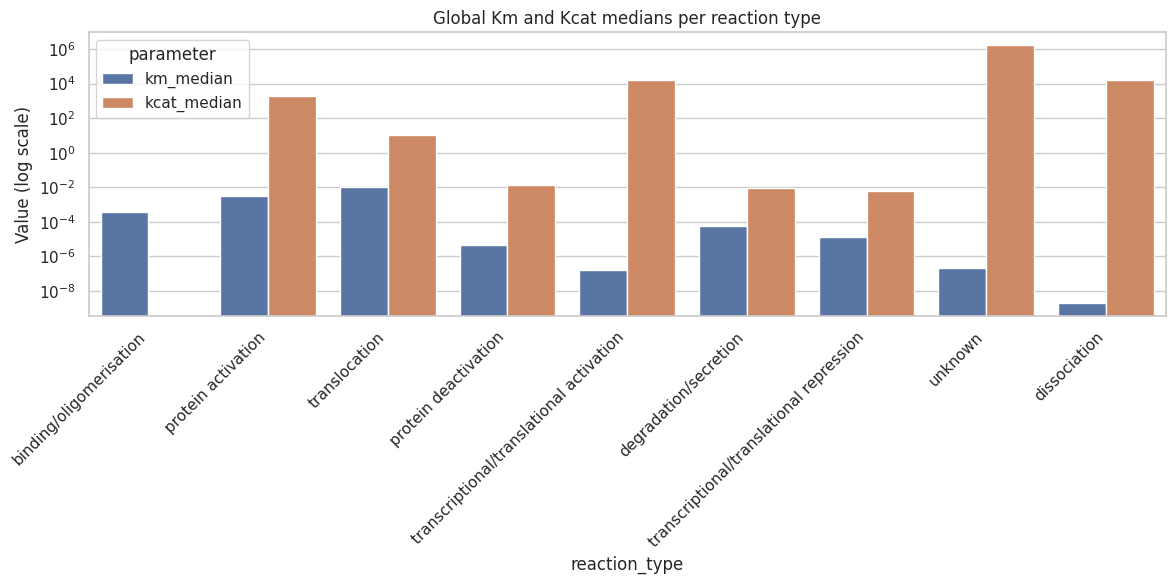

In [13]:
df_global = (
    pd.DataFrame.from_dict(global_kinetics, orient='index')
      .reset_index()
      .rename(columns={'index': 'reaction_type'})
      .melt(id_vars='reaction_type',
            value_vars=['km_median', 'kcat_median'],
            var_name='parameter', value_name='value')
      .dropna()
)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_global, x='reaction_type', y='value', hue='parameter')
plt.xticks(rotation=45, ha='right')
plt.yscale('log')
plt.ylabel('Value (log scale)')
plt.title('Global Km and Kcat medians per reaction type')
plt.tight_layout()
plt.show()

## Build Kinetics Mapper

In [14]:
def build_kinetics_mapper(
    reactions:           dict,
    gathered_kinetics:   pd.DataFrame,
    estimated_kinetics:  pd.DataFrame,
    nib_reactions:       pd.DataFrame,
    global_kinetics:     dict,
    global_median_km:    float,
    global_median_kcat:  float,
) -> callable:
    """Build a self-contained kinetics callable and return it.

    Lookup priority per reaction: gathered → NIB → type median → global median.
    All data is baked into the closure at build time.

    Args:
        reactions:           PSS reactions dict.
        gathered_kinetics:   DataFrame from 'Gathered_Final' sheet.
        estimated_kinetics:  DataFrame from 'Estimated' sheet.
        nib_reactions:       DataFrame from the NIB Excel sheet.
        global_kinetics:     {reaction_type: {km_median, kcat_median}}.
        global_median_km:    Overall Km fallback (mM).
        global_median_kcat:  Overall Kcat fallback (1/s).

    Returns:
        kinetics(reaction_id: str) → {reactant_id: (km_mM, kcat_1s)}
    """
    _reactions          = {rid: dict(r) for rid, r in reactions.items()}
    _gathered           = gathered_kinetics.copy()
    _estimated          = estimated_kinetics.copy()
    _nib                = nib_reactions.copy()
    _global_kinetics    = {k: dict(v) for k, v in global_kinetics.items()}
    _global_km          = global_median_km
    _global_kcat        = global_median_kcat

    def kinetics(reaction_id: str, verbose: bool = False) -> dict[str, tuple]:
        """Return {reactant_id: (km_mM, kcat_1s)} for *reaction_id*.

        Falls back through NIB → type median → global median as needed.
        Self-contained: safe to serialise with dill and load independently.
        """
        import numpy as np
        import statistics

        if reaction_id not in _reactions:
            return {'global': (_global_km, _global_kcat)}

        # Priority 1 — gathered (BRENDA / SABIO-RK / CatPred)
        values = None
        try:
            values = get_kinetics(reaction_id, _reactions, _gathered, _estimated)
        except ValueError:
            pass

        # Priority 2 — NIB
        if values is None:
            try:
                values = get_kinetics_nib(reaction_id, _reactions, _nib, verbose=verbose)
            except ValueError:
                pass

        if not values:
            return {'global': (_global_km, _global_kcat)}

        # Resolve reaction type for type-level fallback
        type_row  = _nib[_nib[(' ', 'reaction_id')] == reaction_id]
        rxn_type  = type_row[(' ', 'reaction_type')].values[0] if not type_row.empty else None
        type_km   = _global_kinetics.get(rxn_type, {}).get('km_median',   _global_km)
        type_kcat = _global_kinetics.get(rxn_type, {}).get('kcat_median', _global_kcat)

        return {
            reactant: (
                km   if km   is not None else (type_km   if type_km   is not None else _global_km),
                kcat if kcat is not None else (type_kcat if type_kcat is not None else _global_kcat),
            )
            for reactant, (km, kcat) in values.items()
        }

    return kinetics

In [15]:
kinetics = build_kinetics_mapper(
    reactions,
    gathered_kinetics,
    estimated_kinetics,
    nib_reactions,
    global_kinetics,
    global_median_km,
    global_median_kcat,
)

### Example usage

In [16]:
first_rxn_id = next(iter(reactions))
print(f"Reaction: {RED}{first_rxn_id}{RESET}")
print(kinetics(first_rxn_id))

Reaction: rx00669
{'s_VPg_cyt_p': (0.00036, 1.02885), 's_LHB1B1_cyt_p': (0.00036, 1.02885)}


### Visualise final Km / Kcat distribution

In [17]:
rows = []
for rxn_id in reactions:
    for specie, (km, kcat) in kinetics(rxn_id).items():
        rows.append({
            'reaction_id': rxn_id,
            'species':     specie,
            'Km':          km,
            'Kcat':        kcat,
            'type':        species[specie]['type'] if specie in species else 'global',
        })
df = pd.DataFrame(rows)

fig = px.scatter(
    df.dropna(subset=['Km', 'Kcat']),
    x='Km', y='Kcat',
    symbol='type', color='reaction_id',
    hover_data=['species', 'Km', 'Kcat', 'reaction_id', 'type'],
    log_x=True, log_y=True,
    title='Km vs Kcat per reaction',
    labels={'Km': 'Km (mM)', 'Kcat': 'Kcat (1/s)', 'reaction_id': 'Reaction ID'},
)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend=dict(title='Reaction ID'))
fig.show()

## Save

In [18]:
with open(PSS_KINETIC_PARAMETER_MAPPER, 'wb') as f:
    dill.dump(kinetics, f)

print(f"Saved kinetics mapper → {PSS_KINETIC_PARAMETER_MAPPER}")

Saved kinetics mapper → /home/ratanasoski/Desktop/Master_Thesis/ThesisRepository/results/kinetic_parameter_mapper.pkl
